ㄴ

# 분류분석

In [3]:
"""
<분류분석에서 사용되는 모델>
- 옛날 모델 : KNN, LogisticRegression(로지스틱레그레이션, 다중분류모델)


- 그다음 향상 모델 : DecisionTree(DT, 결정트리, 의사결정나무라고 칭함, 트리구조 1개 사용)


- 그다음 향상 모델(최신, 트리구조 1개 이상 사용)
  : RandomForest, ExtraTrees


- 그다음 향상 모델(성능 향상 최신, 훈련 중 데이터 섞기 방법 및 속도 개선)
  : GradientBoosting, HistGradientBoosting, XGBoost, LightGBM, 기타 등등


 - 상관관계 검정부터 분류 평가까지 모두 진행...
"""

'\n<분류분석에서 사용되는 모델>\n- 옛날 모델 : KNN, LogisticRegression(로지스틱레그레이션, 다중분류모델)\n\n\n- 그다음 향상 모델 : DecisionTree(DT, 결정트리, 의사결정나무라고 칭함, 트리구조 1개 사용)\n\n\n- 그다음 향상 모델(최신, 트리구조 1개 이상 사용)\n  : RandomForest, ExtraTrees\n\n\n- 그다음 향상 모델(성능 향상 최신, 훈련 중 데이터 섞기 방법 및 속도 개선)\n  : GradientBoosting, HistGradientBoosting, XGBoost, LightGBM, 기타 등등\n\n\n - 상관관계 검정부터 분류 평가까지 모두 진행...\n'

In [4]:
### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

### 상관관계 검정()
from scipy.stats import spearmanr, pearsonr

### 훈련/검증/테스트 데이터로 분리하는 함수
from sklearn.model_selection import train_test_split

### 데이터 스케일링 표준화 클래스
from sklearn.preprocessing import StandardScaler

### 사용할 훈련모델 클래스
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

### 분류분석 오차 확인(평가) 라이브러리
# - 오차행렬표, 오차행렬도(그래프)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

### 분류모델 평가지표(선정기준)
# - 정확도, 정밀도, 재현율, f1-score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [5]:
### 사용할 데이터셋 : 08_wine.csv
# 사용할 변수명 : wine
# 데이터 기본정보 및 기초통계 확인

file_path = "./dataset/08_wine.csv"
wine = pd.read_csv(file_path)
wine.info()
wine.describe()
### (각 특성의 개념)
# - alcohol : 알콜도수
# - sugar : 당도
# - pH : 농도
# - class : 와인종류(0은 레드와인, 1은 화이트와인)

### (분석주제)
# - 알콜도수, 당도, 농도 데이터를 이용하여 와인종류 예측(판단=분류)하기 (회귀에서는 예측 = 추정/ 분류에서는 판단)

### (분류 분석 방법)
# - 예측(분류=판단)하고자하는 변수(종속변수)의 범주 갯수에 따라 분류 방법을 결정함
# - 분류 분석 방법에는 이진분류와 다중분류 방법이 있음(딥러닝에서도 사용되는 개념)
# - 이진분류 : 종속변수의 범주의 갯수가 2개(0 또는 1)인 경우
# - 다중분류 : 종속변수의 범주의 갯수가 3개 이상(0, 1, 2, ...)인 경우

### (데이터 정의)
# - 독립변수(X) : 알콜도수(alcohol), 당도(sugar), 농도(pH)
# - 종속변수(y) : 와인종류(class)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


### 와인의 종류가 몇개인지 종속변수로 사용할 데이터의 범주 확인하기

In [6]:
### 와인의 종류 확인
wine.value_counts("class")
wine["class"].value_counts()

# 컬럼 내 값들 중에 고유한 값들만 추출(중복 제거)
wine["class"].unique()

### 0과 1의 범주 2개만 존재하는 이진분류가 가능한 데이터...

array([0., 1.])

In [7]:
wine.value_counts("class", normalize=True)

class
1.0    0.753886
0.0    0.246114
Name: proportion, dtype: float64

### 상관관계 분석 및 상과관계 검정하기

In [8]:
### 상관관계 계수 확인하기
# - 상관관계 확인시에는 독립변수 및 종속변수로 나누지 않고 합니다.
# - 상관관계 검정시에는 독립변수와 종속변수로 구분해야함


### <상관관계 분석 및 검증 순서>
# 1. 상관관계 메트릭스표 확인(상관관계 계수 확인)
#   -> *데이터프레임.corr() 후 변수 담기 corr_matrix
# 2. 상관관계도 시각화(히트맵-상관관계 계수를 색으로 확인)
#   -> sns.heatmap
# 3. 상관행렬도 시각화(산점도 분포 확인-선형/비선형 형태 확인)
#   -> sns.pairplot

# 4. 상관관계 검정
#    : 종속변수와 독립변수 각각에 대한 유의미성 확인
#    : 독립과 종속변수 각각 구분하여 진행
#      (독립변수 변수명 : data, 종속변수 변수명 : target)
#   -> data = wine에서 class를 drop / target은 wine에서 ["class"]만 담기
#    : 검정방법 (스피어만, 피어슨 방법 사용). p-value 기준 0.05
#   -> spearmanr(독립변수, 종속변수), pearsonr(독립변수, 종속변수)


#### 상관관계 확인하기 (1번~3번 진행)

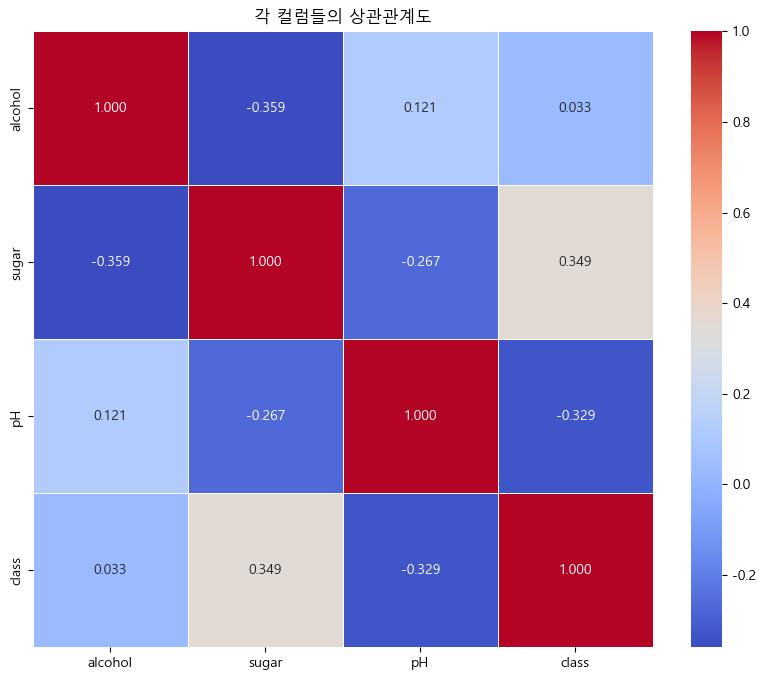

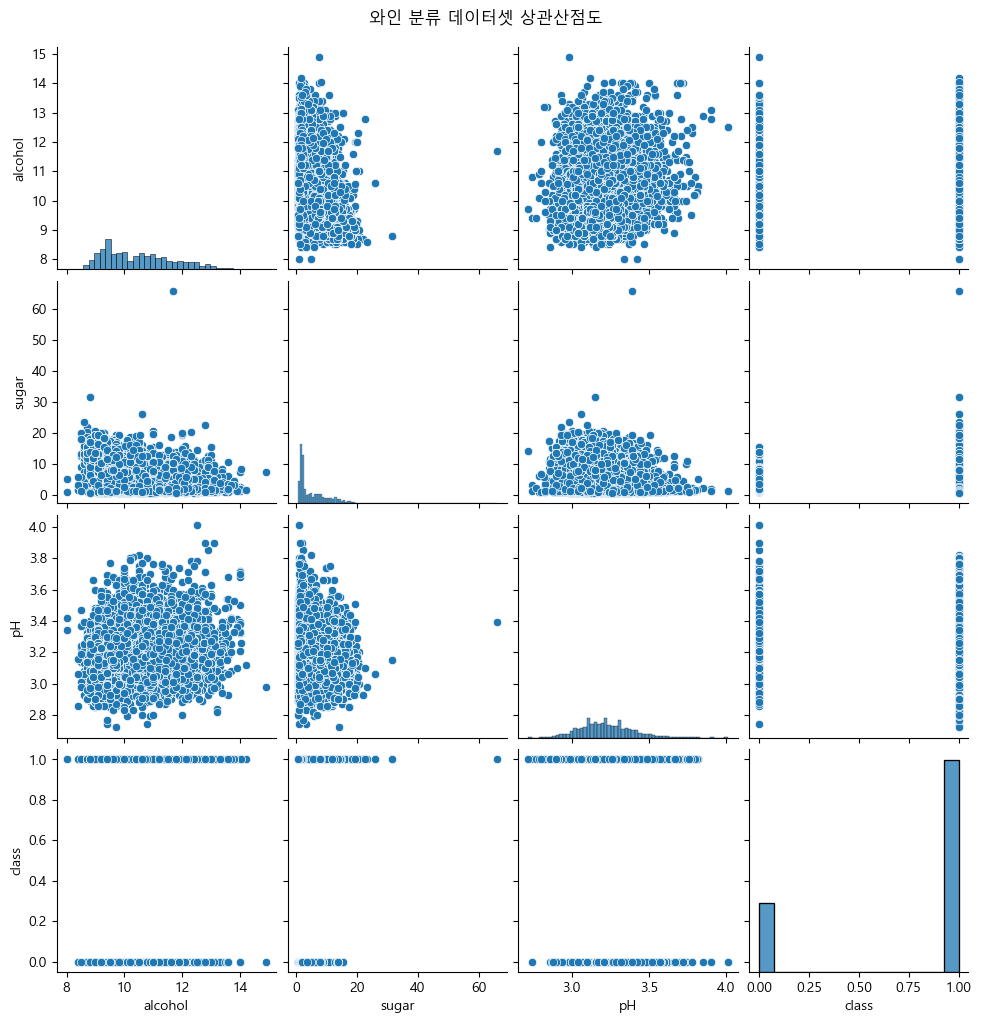

In [9]:
# 1.상관관계 메트릭스표 확인
corr_matrix=wine.corr()
corr_matrix
# 2. 상관관계도 시각화(히트맵-상관관계 계수를 색으로 확인)
plt.figure(figsize=(10,8))
plt.title("각 컬럼들의 상관관계도")
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5)
# sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", linewidths=0.5) 몰랐음
# alcohol과 class의 상관관계는 매우 낮다

# 3. 상관행렬도 시각화

sns.pairplot(wine)
plt.suptitle("와인 분류 데이터셋 상관산점도", y=1.02)
plt.show()
# alcohol과 pH가 약간 선형인 관계

#### 상관관계 검정(유의미성 : p-value) 확인하기(4번 진행)

In [ ]:
# 4. 상관관계 검정
#    : 종속변수와 독립변수 각각에 대한 유의미성 확인
#    : 독립과 종속변수 각각 구분하여 진행
#      (독립변수 변수명 : data, 종속변수 변수명 : target)
data = wine.drop(columns=["class"])
data = wine.iloc[:,:-1]
data
target = wine["class"] # 종속변수는 1차원이어야 함.
target
print(data.shape, target.shape)
# 꼭 차원 확인해보기!!!!!!!
data.shape, target.shape
#   -> data = wine에서 class를 drop / target은 wine에서 ["class"]만 담기
#    : 검정방법 (스피어만, 피어슨 방법 사용). p-value 기준 0.05
#   -> spearmanr(독립변수, 종속변수), pearsonr(독립변수, 종속변수)===
print("============================================spearman방식==============================================")
for col in data.columns:
    s, p = spearmanr(data[col], target)
    if p < 0.05:
        print(f"{col}과 class와의 스피어만 검정해보았을 때, \n유의미 계수는 {p:.4f}로 p-value < 0.05 유의미함")
    if p >= 0.05:
        print(f"{col}과 class와의 스피어만을 검정해보았을 때, \n유의미 계수는 {p:.4f}로 p-value >= 0.05 유의미하지 않음")
print("=============================================pearson방식================================================")
for col in data.columns:
    s, p = pearsonr(data[col], target)
    if p < 0.05:
        print(f"{col}과 class와의 피어슨 검정해보았을 때, \n유의미 계수는 {p:.4f} 로 p-value < 0.05 유의미함")
    if p >= 0.05:
        print(f"{col}과 class와의 피어슨 검정해보았을 때, \n유의미 계수는 {p:.4f}로 p-value >= 0.05 유의미하지 않음")



(6497, 3) (6497,)
============================================spearman방식==============================================
alcohol과 class와의 스피어만을 검정해보았을 때, 
유의미 계수는 0.1819로 p-value >= 0.05 유의미하지 않음
sugar과 class와의 스피어만 검정해보았을 때, 
유의미 계수는 0.0000로 p-value < 0.05 유의미함
pH과 class와의 스피어만 검정해보았을 때, 
유의미 계수는 0.0000로 p-value < 0.05 유의미함
=============================================pearson방식================================================
alcohol과 class와의 피어슨 검정해보았을 때, 
유의미 계수는 0.0079 로 p-value < 0.05 유의미함
sugar과 class와의 피어슨 검정해보았을 때, 
유의미 계수는 0.0000 로 p-value < 0.05 유의미함
pH과 class와의 피어슨 검정해보았을 때, 
유의미 계수는 0.0000 로 p-value < 0.05 유의미함


In [11]:
### (종합 해석)
# - 상관관계 계수의 경우 알콜의 계수값은 0.03으로 매우 낮은 상관성을 띄고 있으며,
#   -> 당도 및 농도의 경우에는 0.3 이상으로 낮지만 상관성을 띄고 있음
#   -> 알콜의 경우 향후 모델 훈련 시 제외하고 진행하여,
#      성능에 영향을 미치는지도 확인할 필요성이 있음


# - 전체 특성들의 분포를 볼 때,
#   -> 와인종류의 0과 1을 기준으로 `수평`` 분포를 나타내고 있기에
#   -> 분류 분석으로 진행하는 것이 타당함


### (해석)
# - 실제 문서에 작성할 때는 한가지 방법으로만 작성
# - 하지만, 분석가 입장에서는 모두다 확인 후 최종 훈련이 완료된 다음에 결정


### 선형/비선형 모두 가능한 검정방식인 스피어만 검정 방법에서는(현장에서 주로 스피어만 방식)
#   - 알콜의 경우 p-value >= 0.05 이므로, 유의미하지 않았으며,
#   - 당도 및 농도의 경우 p-value < 0.05를 만족하여 유의미한 것으로 확인됨


### 선형을 주로 검정하는 피어슨 검정 방법에서는(선형 측정)
#   - 모든 특성들이 p-value < 0.05를 만족하여 유의미하므로, 모두 훈련에 사용가능


### 따라서, 이론상으로는 스피어만 방식을 준수해야하나,
#   모델 훈련 시에는 모든 특성을 적용하여 훈련 후,
#   유의미하지 않은 알콜을 제외하고, 재훈련하여 비교할 필요성은 있음

### 훈련 : 테스트 = 8:2로 분리하기

In [12]:
"""
변수명 :train_input, train_target, test_input, test_target
"""

### stratify=target : 분리 비율에 맞게 종속변수의 범주값들을 분리
train_input,  test_input, train_target, test_target = train_test_split(data, target, test_size=0.2 ,stratify=target ,random_state=42)
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)

(5197, 3) (5197,)
(1300, 3) (1300,)


### 데이터스케일링(표준화)하기

In [13]:
### StandardScaler로 스케일링 처리하기
# 변수명 : ss
# 훈련 및 테스트 스케일링 변수명 : train_scaled, test_scaled
#클래스 생성
ss = StandardScaler()
#패턴찾기
ss.fit(train_input)
#변환시키기
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)

print(train_scaled.shape, train_target.shape)
print(test_scaled.shape, test_target.shape)

(5197, 3) (5197,)
(1300, 3) (1300,)


## KNN 모델로 훈련(학습)후 과적합 여부 확인하기

In [ ]:
### KNN 분류 모델로 과적합만 확인하기
# - 이웃의 갯수는 5개 사용
# 클래스생성
knr = KNeighborsClassifier()
knr
# 훈련시키기
knr.fit(train_scaled, train_target)
### 분류분석에서는 정확도(score)라는 용어를 사용함(회귀에서는 결정계수라 표현함)
train_score = knr.score(train_scaled, train_target)
test_score = knr.score(test_scaled, test_target)
print(f"훈련정확도:{train_score:.4f}, 테스트정확도:{test_score: .4f}")
# 과적합 여부
print(train_score-test_score)
## 해석
# - 과적합 아니고 일반화 잘 되었음.
# - score() 함수의 결과값은 정확도로 확률(%)을 의미함(0 ~ 1 => 0% ~ 100%를 의미함)

훈련정확도:0.9042, 테스트정확도: 0.8408
0.06340625508799447


## 로지스틱레그레이션(LogisticRegression) 모델로 과적합 여부 확인하기

In [15]:
"""
- 이름은 회귀(Regression)이지만, 분류분석에 사용되는 모델임
- 다중분류(즉 여러 특성들을 가지는 데이터 분류)에 사용됨(다중회귀모델과 동일한 개념을 따름)
"""

"""
<로지스틱 레그레이션 모델>
 - 이름은 회귀이지만, 분류분석에 사용되는 모델 입니다.
 - 내부적으로 사용되는 산술식이 "다중회귀" 모델의 알고리즘을 사용
 - 이진분류, 다중분류에 사용됩니다.
 
<이진분류 vs 다중분류>
 - 종속변수의 범주의 갯수에 따라 이진 또는 다중 분류로 구분합니다.
 - 이진분류 : 범주가 2개인 경우 (둘중 하나 선택, 남자/여자, 0/1)
 - 다중분류 : 범주가 3개이상인 경우(여러개 중 하나 선택, 0~n)


<로지스틱레그레이션 모델 성능 향상을 위한 하이퍼파라메터 튜닝>
 - 튜닝에 사용되는 기본적인 변수명 : C(규제강도), max_iter(훈련 반복횟수)
 - C(규제강도)
   : 규제강도는 릿지 또는 라쏘에서 사용한 alpha 규제강도와 동일한 개념으로
     복잡도를 높이거나 낮추는 방식을 적용함
   : C의 기본값은 = 1
   : C 값의 범위 : 0.001~100 사이를 주로 사용
   : C의 값이 커질수록 규제를 완화시키며, 작을수록 규제를 강화시킴
   
 - max_iter(훈련 반복횟수)
   : 훈련을 여러번 반복하여 훈련의 정확도를 높임
   : max_iter의 기본값은 = 100
   : max_iter의 범위 : 1이상~
   
***(중요) 하이퍼파라메터 튜닝을 한다고 해서 꼭~ 모델의 성능이 좋아진다고 볼수는 없음
          오히려 나빠지는 경우도 가끔 발생함
"""

'\n<로지스틱 레그레이션 모델>\n - 이름은 회귀이지만, 분류분석에 사용되는 모델 입니다.\n - 내부적으로 사용되는 산술식이 "다중회귀" 모델의 알고리즘을 사용\n - 이진분류, 다중분류에 사용됩니다.\n \n<이진분류 vs 다중분류>\n - 종속변수의 범주의 갯수에 따라 이진 또는 다중 분류로 구분합니다.\n - 이진분류 : 범주가 2개인 경우 (둘중 하나 선택, 남자/여자, 0/1)\n - 다중분류 : 범주가 3개이상인 경우(여러개 중 하나 선택, 0~n)\n\n\n<로지스틱레그레이션 모델 성능 향상을 위한 하이퍼파라메터 튜닝>\n - 튜닝에 사용되는 기본적인 변수명 : C(규제강도), max_iter(훈련 반복횟수)\n - C(규제강도)\n   : 규제강도는 릿지 또는 라쏘에서 사용한 alpha 규제강도와 동일한 개념으로\n     복잡도를 높이거나 낮추는 방식을 적용함\n   : C의 기본값은 = 1\n   : C 값의 범위 : 0.001~100 사이를 주로 사용\n   : C의 값이 커질수록 규제를 완화시키며, 작을수록 규제를 강화시킴\n   \n - max_iter(훈련 반복횟수)\n   : 훈련을 여러번 반복하여 훈련의 정확도를 높임\n   : max_iter의 기본값은 = 100\n   : max_iter의 범위 : 1이상~\n   \n***(중요) 하이퍼파라메터 튜닝을 한다고 해서 꼭~ 모델의 성능이 좋아진다고 볼수는 없음\n          오히려 나빠지는 경우도 가끔 발생함\n'

In [16]:
### 로지스틱레그레이션으로 훈련 후 과적합 여부 확인까지만 진행
# - 규제강도=0.13, 반복횟수=100회
lr = LogisticRegression(C=0.13)
lr
# 훈련시키기
lr.fit(train_scaled, train_target)
# 정확도측정
train_score=lr.score(train_scaled, train_target)
test_score=lr.score(test_scaled, test_target)
# 과적합 여부
print(f"훈련정확도는{ train_score:.5f}, 테스트정확도는{ test_score:.5f}입니다. \n과적합여부:{train_score-test_score:.5f}")
### 훈련 정확도는 낮지만, 일반화는 잘 되었음

훈련정확도는0.78218, 테스트정확도는0.77615입니다. 
과적합여부:0.00603


## 의사결정나무=결정트리(DecisionTree, DT 모델이라고 칭함)

In [17]:
"""
<결정트리(DT) 모델>
 - 트리(나무) 구조 처럼, 가지를 뻗어나가면서 훈련을 한다고 해서 Tree라고 칭함
 - 가지를 뻗어나가는 방법은 모델 스스로 랜덤하게 뻗어 나갑니다.
 - 사용되는 데이터도 랜덤하게 추출하여 사용함
   다만, 하이퍼파라메터를 통해 제어가 가능함
 - 모델 생성시 랜덤 규칙을 지정하는 것이 좋음
 - 이전에는 옛날 분류모델과의 비교 모델로 사용되는 최신모델이었으나,
   최근에는 앙상블 모델이 나오면서 비교 대상 모델로 수행하는 편임
 - 사용패키지 : sklearn.tree
 - 사용모델(클래스) : DecisionTreeClassifier
 - 훈련 등 사용함수는 기존 모델들과 동일(fit, score, predict)
"""


'\n<결정트리(DT) 모델>\n - 트리(나무) 구조 처럼, 가지를 뻗어나가면서 훈련을 한다고 해서 Tree라고 칭함\n - 가지를 뻗어나가는 방법은 모델 스스로 랜덤하게 뻗어 나갑니다.\n - 사용되는 데이터도 랜덤하게 추출하여 사용함\n   다만, 하이퍼파라메터를 통해 제어가 가능함\n - 모델 생성시 랜덤 규칙을 지정하는 것이 좋음\n - 이전에는 옛날 분류모델과의 비교 모델로 사용되는 최신모델이었으나,\n   최근에는 앙상블 모델이 나오면서 비교 대상 모델로 수행하는 편임\n - 사용패키지 : sklearn.tree\n - 사용모델(클래스) : DecisionTreeClassifier\n - 훈련 등 사용함수는 기존 모델들과 동일(fit, score, predict)\n'

In [18]:
### 훈련 시키고 과적합 여부만 확인하기
# - 랜덤규칙 : 42번 설정하여 클래스 생성
# 클래스생성
dt = DecisionTreeClassifier(random_state=42)
# 훈련
dt.fit(train_scaled, train_target)
# 정확도
train_score=dt.score(train_scaled, train_target)
test_score=dt.score(test_scaled, test_target)
# 과적합 여부
print(f"훈련정확도는{ train_score:.5f}, 테스트 정확도는{ test_score:.5f}입니다. 과적합 여부는{train_score-test_score}")
# <해석>
# 과대적합임.
dt

훈련정확도는0.99788, 테스트 정확도는0.86462입니다. 과적합 여부는0.1332680096505381


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


### DT 모델로 하이퍼파라메터 튜닝 진행

In [19]:
"""
<트리 가지치기 갯수 제한을 통한 튜닝>
 - 가지치기 갯수 제한 변수명(트리의 깊이를 의미함) : max_depth
 - 트리가 가지를 뻗어나가는 횟수를 제한
 - 가지가 뻗어나가는 횟수를 제한하였더라도,
   제한된 횟수 이전에 종속변수가 결정된다면 훈련을 자동 종료함
 - 종속변수가 결정되는 시점이 리프노드(leaf-node)가 결정되는 시점임
 - 리프노드가 결정되지 않으면 -> 계속 가지를 뻗어나가면서 규칙노드를 수행함
 - 이때 가지가 뻗어나가는 깊이를 트리의 깊이(max_depth)라고 칭함
   -> 트리의 깊이는 루트노드(root-node) 다음부터 깊이가 count 됨
 - 사람의 개입 시점 : 하이퍼파라메터를 통해 제어할 수 있는 값을 정의할 수는 있지만,
                    내부에서 랜덤하게 진행되는 과정은 사람이 개입하지 못함
"""


'\n<트리 가지치기 갯수 제한을 통한 튜닝>\n - 가지치기 갯수 제한 변수명(트리의 깊이를 의미함) : max_depth\n - 트리가 가지를 뻗어나가는 횟수를 제한\n - 가지가 뻗어나가는 횟수를 제한하였더라도,\n   제한된 횟수 이전에 종속변수가 결정된다면 훈련을 자동 종료함\n - 종속변수가 결정되는 시점이 리프노드(leaf-node)가 결정되는 시점임\n - 리프노드가 결정되지 않으면 -> 계속 가지를 뻗어나가면서 규칙노드를 수행함\n - 이때 가지가 뻗어나가는 깊이를 트리의 깊이(max_depth)라고 칭함\n   -> 트리의 깊이는 루트노드(root-node) 다음부터 깊이가 count 됨\n - 사람의 개입 시점 : 하이퍼파라메터를 통해 제어할 수 있는 값을 정의할 수는 있지만,\n                    내부에서 랜덤하게 진행되는 과정은 사람이 개입하지 못함\n'

In [20]:
### DT 모델에 트리의 깊이를 50으로하여 과적합 여부 확인까지만 해보기
### 훈련 시키고 과적합 여부만 확인하기
# - 랜덤규칙 : 42번 설정하여 클래스 생성
# 클래스생성 (기본값: 50)
dt = DecisionTreeClassifier(random_state=42, max_depth=50)
# 훈련
dt.fit(train_scaled, train_target)
# 정확도
train_score=dt.score(train_scaled, train_target)
test_score=dt.score(test_scaled, test_target)
# 과적합 여부
print(f"훈련정확도는{ train_score:.5f}, 테스트 정확도는{ test_score:.5f}입니다. 과적합 여부는{train_score-test_score:.5f}")
# <해석>
# 과대적합임.
dt

훈련정확도는0.99788, 테스트 정확도는0.86462입니다. 과적합 여부는0.13327


,criterion,'gini'
,splitter,'best'
,max_depth,50
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [21]:
"""
트리의 깊이 2개~100개까지 반복 수행하면서 가장 좋은 시점의 트리 깊이를 확인해 보세요.
"""
model = "model"
model_list=[]
for depth in range(2, 101, 1):
    # 클래스 생성/ for 문이 끝날 떄가지 99개의 메모리를 차지하고 있어서 메모리 낭비됨.
    dt = DecisionTreeClassifier(random_state=42, max_depth=depth)
    # 훈련
    dt.fit(train_scaled, train_target)
    # 정확도
    train_score=dt.score(train_scaled, train_target)
    test_score=dt.score(test_scaled, test_target)
    # 과적합 여부
    print(f"훈련정확도는{ train_score:.5f}, 테스트 정확도는{ test_score:.5f}입니다. 과적합 여부는{train_score-test_score:.5f}")
    if (train_score != 1) and (train_score > test_score) and ((train_score-test_score)<0.1):
        model_list.append({model : [
            dt, 
            (f"훈련정확도: {train_score}"), 
            (f"테스트정확도: {test_score}"), 
            (f"과적합여부: {train_score-test_score}")]
            })
    # <해석>
    # 과대적합임.



훈련정확도는0.80623, 테스트 정확도는0.81077입니다. 과적합 여부는-0.00453
훈련정확도는0.84587, 테스트 정확도는0.84077입니다. 과적합 여부는0.00510
훈련정확도는0.85953, 테스트 정확도는0.85231입니다. 과적합 여부는0.00723
훈련정확도는0.87185, 테스트 정확도는0.85769입니다. 과적합 여부는0.01416
훈련정확도는0.87781, 테스트 정확도는0.84846입니다. 과적합 여부는0.02935
훈련정확도는0.88801, 테스트 정확도는0.85154입니다. 과적합 여부는0.03647
훈련정확도는0.90033, 테스트 정확도는0.85846입니다. 과적합 여부는0.04187
훈련정확도는0.91245, 테스트 정확도는0.86154입니다. 과적합 여부는0.05091
훈련정확도는0.92553, 테스트 정확도는0.86154입니다. 과적합 여부는0.06400
훈련정확도는0.94131, 테스트 정확도는0.85769입니다. 과적합 여부는0.08362
훈련정확도는0.95382, 테스트 정확도는0.86538입니다. 과적합 여부는0.08843
훈련정확도는0.96806, 테스트 정확도는0.86231입니다. 과적합 여부는0.10575
훈련정확도는0.97576, 테스트 정확도는0.86615입니다. 과적합 여부는0.10960
훈련정확도는0.98345, 테스트 정확도는0.86692입니다. 과적합 여부는0.11653
훈련정확도는0.98711, 테스트 정확도는0.86923입니다. 과적합 여부는0.11788
훈련정확도는0.99038, 테스트 정확도는0.86231입니다. 과적합 여부는0.12807
훈련정확도는0.99307, 테스트 정확도는0.86923입니다. 과적합 여부는0.12384
훈련정확도는0.99480, 테스트 정확도는0.86692입니다. 과적합 여부는0.12788
훈련정확도는0.99577, 테스트 정확도는0.86692입니다. 과적합 여부는0.12884
훈련정확도는0.99654, 테스트 정확도는0.87077입니다. 과적합 여부는0.12577

In [22]:
"""
트리의 깊이 2개~100개까지 반복 수행하면서 가장 좋은 시점의 트리 깊이를 확인해 보세요.
"""
### for 문 내에서 클래스를 생성하면 반복 횟수만큼 클래스가 생성되어 메모리를 낭비함.
# - 따라서 전역변수로 클래스를 생성한 후 하나의 메모리 주소만 사용
# - for문 내에서는 클래스 메모리 내에 있는 트리깊이 변수의 값만 수정하면서 훈련(fit)을 반복하면
# -> 메모리를 낭비하지 않을 수 있음
dt = DecisionTreeClassifier(random_state=42)
model = "model"
model_list=[]
for depth in range(2, 101, 1):
    # 트리깊이 변수의 값만 수정하면서 훈련(fit)을 반복
    dt.max_depth=depth
    # 훈련
    dt.fit(train_scaled, train_target)
    # 정확도
    train_score=dt.score(train_scaled, train_target)
    test_score=dt.score(test_scaled, test_target)
    # 과적합 여부
    print(f"훈련정확도는{ train_score:.5f}, 테스트 정확도는{ test_score:.5f}입니다. 과적합 여부는{train_score-test_score:.5f}")
    if (train_score != 1) and (train_score > test_score) and ((train_score-test_score)<0.1):
        model_list.append({model : [
            dt, 
            (f"훈련정확도: {train_score}"), 
            (f"테스트정확도: {test_score}"), 
            (f"과적합여부: {train_score-test_score}")]
            })
    # <해석>
    # 과대적합임.



훈련정확도는0.80623, 테스트 정확도는0.81077입니다. 과적합 여부는-0.00453
훈련정확도는0.84587, 테스트 정확도는0.84077입니다. 과적합 여부는0.00510
훈련정확도는0.85953, 테스트 정확도는0.85231입니다. 과적합 여부는0.00723
훈련정확도는0.87185, 테스트 정확도는0.85769입니다. 과적합 여부는0.01416
훈련정확도는0.87781, 테스트 정확도는0.84846입니다. 과적합 여부는0.02935
훈련정확도는0.88801, 테스트 정확도는0.85154입니다. 과적합 여부는0.03647
훈련정확도는0.90033, 테스트 정확도는0.85846입니다. 과적합 여부는0.04187
훈련정확도는0.91245, 테스트 정확도는0.86154입니다. 과적합 여부는0.05091
훈련정확도는0.92553, 테스트 정확도는0.86154입니다. 과적합 여부는0.06400
훈련정확도는0.94131, 테스트 정확도는0.85769입니다. 과적합 여부는0.08362
훈련정확도는0.95382, 테스트 정확도는0.86538입니다. 과적합 여부는0.08843
훈련정확도는0.96806, 테스트 정확도는0.86231입니다. 과적합 여부는0.10575
훈련정확도는0.97576, 테스트 정확도는0.86615입니다. 과적합 여부는0.10960
훈련정확도는0.98345, 테스트 정확도는0.86692입니다. 과적합 여부는0.11653
훈련정확도는0.98711, 테스트 정확도는0.86923입니다. 과적합 여부는0.11788
훈련정확도는0.99038, 테스트 정확도는0.86231입니다. 과적합 여부는0.12807
훈련정확도는0.99307, 테스트 정확도는0.86923입니다. 과적합 여부는0.12384
훈련정확도는0.99480, 테스트 정확도는0.86692입니다. 과적합 여부는0.12788
훈련정확도는0.99577, 테스트 정확도는0.86692입니다. 과적합 여부는0.12884
훈련정확도는0.99654, 테스트 정확도는0.87077입니다. 과적합 여부는0.12577

In [23]:
model_list

[{'model': [DecisionTreeClassifier(max_depth=100, random_state=42),
   '훈련정확도: 0.8458726188185491',
   '테스트정확도: 0.8407692307692308',
   '과적합여부: 0.005103388049318314']},
 {'model': [DecisionTreeClassifier(max_depth=100, random_state=42),
   '훈련정확도: 0.8595343467385029',
   '테스트정확도: 0.8523076923076923',
   '과적합여부: 0.007226654430810608']},
 {'model': [DecisionTreeClassifier(max_depth=100, random_state=42),
   '훈련정확도: 0.8718491437367712',
   '테스트정확도: 0.8576923076923076',
   '과적합여부: 0.014156836044463605']},
 {'model': [DecisionTreeClassifier(max_depth=100, random_state=42),
   '훈련정확도: 0.8778141235328074',
   '테스트정확도: 0.8484615384615385',
   '과적합여부: 0.029352585071268922']},
 {'model': [DecisionTreeClassifier(max_depth=100, random_state=42),
   '훈련정확도: 0.8880123147969983',
   '테스트정확도: 0.8515384615384616',
   '과적합여부: 0.03647385325853669']},
 {'model': [DecisionTreeClassifier(max_depth=100, random_state=42),
   '훈련정확도: 0.9003271117952665',
   '테스트정확도: 0.8584615384615385',
   '과적합여부: 0.0418655733

### 훈련(학습)에 사용된 독립변수의 특성들 중에 얼마나 훈련에 영향을 미치는지 확률적을 확인하기

In [24]:
"""
<특성 중요도(feature importances)>
 - 훈련에 사용된 독립변수의 특성들이
 - 종속변수를 찾는데 얼마나 영향을 미쳤는지를 확인하여
 - 특성이 미친 영향을 비율(%)로 나타냅니다.
 - 일부 모델들은 특성 중요도 값을 제공하지 않는 모델도 있음
 - 특성 중요도는 분류모델에서 사용됨
"""

'\n<특성 중요도(feature importances)>\n - 훈련에 사용된 독립변수의 특성들이\n - 종속변수를 찾는데 얼마나 영향을 미쳤는지를 확인하여\n - 특성이 미친 영향을 비율(%)로 나타냅니다.\n - 일부 모델들은 특성 중요도 값을 제공하지 않는 모델도 있음\n - 특성 중요도는 분류모델에서 사용됨\n'

In [25]:
### 특성 중요도 확인하기(영향을 미치는 정도)
# - alcohol, sugar, pH
print(dt.feature_importances_)

### (해석)
# - 레드와인과 화이트와인 분류에는 당도(sugar)가 가장 큰 영향을 미치고 있으며,
# - 다음으로 농도(pH), 알콜(alcohol) 순으로 영향을 미치고 있음
# - 농도와 알콜은 유사한 비율로 영향을 미치고 있음

### 따라서, 상관관계계수가 가장 낮았던 알콜(alcohol)의 경우와
#   스피어만 상관관계 검정에서 유의미 하지 않았던 알콜의 경우에는
#  -> 특성 중요도의 결과에 따라 훈련에는 영향을 미치기에
#     훈련에 참여시키는 것이 타당하다고 여겨짐

#  -> 그럼에도 불구하고 유의미하지 않았던 알콜을 제외하고 훈련을 시켜본 후 비교 필요..
#  ** 만약 특성중요도에서도 매우 낮게 나온(0.1 이하) 특성이 있다면 제외 후 훈련 정확도 비교..

[0.23393909 0.51450301 0.2515579 ]


### 유의미 하지 않았던 알콜 특성을 제외하고 훈련 시키기

In [26]:
### 기존 훈련 성능과 비교를 위해 : max_depth는 12로 정의한 후 훈련 시키기
# DecisionTreeClassifier(max_depth=12), '훈련정확도: 0.9538195112564941','테스트정확도: 0.8653846153846154','과적합여부: 0.0884348958718787']

### 훈련 및 테스트 데이터에서 알콜 특성 제거하기
# - 훈련 독립변수명 : train_scaled2
# - 테스트 독립변수명 : test_scaled2

train_scaled2 = train_scaled[:,1:]
test_scaled2 = test_scaled[:,1:]
print(train_scaled2.shape, train_target.shape)
print(test_scaled2.shape, test_target.shape)

(5197, 2) (5197,)
(1300, 2) (1300,)


![alt text](image.png)

In [27]:
# 클래스 생성
dt = DecisionTreeClassifier(max_depth=12, random_state=42)
# 훈련시키기
dt.fit(train_scaled2, train_target)
# 정확도 
train_score2=dt.score(train_scaled2, train_target)
test_score2=dt.score(test_scaled2, test_target)
# 과적합 여부
print(f"훈련정확도{train_score2}, 테스트 정확도{test_score2}, 과적합여부{train_score2-test_score2}")
# DecisionTreeClassifier(max_depth=12), '훈련정확도: 0.9538195112564941','테스트정확도: 0.8653846153846154','과적합여부: 0.0884348958718787']
# 훈련 및 테스트 정확도 떨어짐. 일반화 수준은 향상됨.

훈련정확도0.9032133923417356, 테스트 정확도0.8407692307692308, 과적합여부0.062444161572504764


### 모든 특성을 이용하여 트리 깊이 12일 때 하이퍼파라메터를 이용하여 훈련시키기

In [28]:
# 클래스생성 (기본값: 50)
dt = DecisionTreeClassifier(random_state=42, max_depth=12)
# 훈련
dt.fit(train_scaled, train_target)
# 정확도
train_score=dt.score(train_scaled, train_target)
test_score=dt.score(test_scaled, test_target)
# 과적합 여부
print(f"훈련정확도는{ train_score:.5f}, 테스트 정확도는{ test_score:.5f}입니다. 과적합 여부는{train_score-test_score:.5f}")

훈련정확도는0.95382, 테스트 정확도는0.86538입니다. 과적합 여부는0.08843


### 분류모델 평가하기

In [29]:
"""
<분류 모델 평가 방법>
 - 예측(predict)이 사전에 진행 된 후 예측결과를 이용하여 평가를 진행합니다.
 - "***정확도, 정밀도, ****재현율, **F1-Score" 값을 이용해서 평가합니다. / *갯수 : 선정개수
 - 예측(predict) 시 부정확한 오류가 있는지 확인하는 절차입니다.
 - 부정확한 오류 : 예측이 잘 못된 경우를 의미합니다.
 - 오류의 종류 : 긍정적 오류(1종오류), 부정적 오류(2종오류)로 나뉩니다.
 - 오류 확인 방법 : 오차행렬(혼동행렬)표, 오차행렬도(혼동행렬도)를 통해 확인
 
<평가 기준>
 - 정확도를 이용하여 과적합여부 확인(보통 훈련 시키는 시점에 진행, 일반화 확인을 위해)
 - 평가기준 : 일반화된 상태를 전제로 진행합니다.
   -- 주로 -> 재현율이 높고, F1-Score값이 높은 모델을 선정
   -- 재현율이 낮은 경우에는 부정적 오류(부정확한 오류)가 있다는 의미임
 - 정확도, 정밀도, 재현율, F1-Score 모든 값의 범위 : 0~1 사이의 값(확율을 의미함)
                                                  (1에 가까울 수록 좋음)
 - (주의사항)
    -- 정확도가 높더라도 재현율이 낮은 경우에는 훈련모델 사용을 고려해야함
   
 - (최종 모델 선정 기준)
    -- 일반화 > 정확도 & 재현율 > F1-Score > 정밀도
"""

# 정확도 : ex.10개중에 8개 맞으면 80%

# 재현율 : 정답을 얼마나 오답으로 맞혔나, 오답을 얼마나 정답으로 맞혔나. 부정적오류가 많으면 재현율 떨어짐


'\n<분류 모델 평가 방법>\n - 예측(predict)이 사전에 진행 된 후 예측결과를 이용하여 평가를 진행합니다.\n - "***정확도, 정밀도, ****재현율, **F1-Score" 값을 이용해서 평가합니다. / *갯수 : 선정개수\n - 예측(predict) 시 부정확한 오류가 있는지 확인하는 절차입니다.\n - 부정확한 오류 : 예측이 잘 못된 경우를 의미합니다.\n - 오류의 종류 : 긍정적 오류(1종오류), 부정적 오류(2종오류)로 나뉩니다.\n - 오류 확인 방법 : 오차행렬(혼동행렬)표, 오차행렬도(혼동행렬도)를 통해 확인\n \n<평가 기준>\n - 정확도를 이용하여 과적합여부 확인(보통 훈련 시키는 시점에 진행, 일반화 확인을 위해)\n - 평가기준 : 일반화된 상태를 전제로 진행합니다.\n   -- 주로 -> 재현율이 높고, F1-Score값이 높은 모델을 선정\n   -- 재현율이 낮은 경우에는 부정적 오류(부정확한 오류)가 있다는 의미임\n - 정확도, 정밀도, 재현율, F1-Score 모든 값의 범위 : 0~1 사이의 값(확율을 의미함)\n                                                  (1에 가까울 수록 좋음)\n - (주의사항)\n    -- 정확도가 높더라도 재현율이 낮은 경우에는 훈련모델 사용을 고려해야함\n   \n - (최종 모델 선정 기준)\n    -- 일반화 > 정확도 & 재현율 > F1-Score > 정밀도\n'

### 훈련 및 테스트 데이터로 예측하기

In [30]:
# 예측하기
train_pred = dt.predict(train_scaled)
test_pred = dt.predict(test_scaled)

print(train_pred.shape)
print(test_pred.shape)



(5197,)
(1300,)


### 오차행렬표(혼동행렬표) 확인하기

In [31]:
### 종속변수_범주명
print(dt.classes_)

### 오차행렬표(혼동행렬표) : (실제정답, 예측값, 종속변수 범주 라벨)
confusion_matrix(train_target, train_pred, labels=dt.classes_)

"""
<오차행렬표 해석 방법>
 - 0행 0열 : 0을 0으로 잘 맞춘 갯수 (1207)
 - 1행 1열 : 1을 1로 잘 맞춘 갯수 (3750)


 - 0행 1열 : 0을 1로 잘못맞춘 갯수(긍정적 오류) (72)
 - 1행 0열 : 1을 0으로 잘못맞춘 갯수(부정적 오류 - 치명적 오류 - 재현율에 영향을 미침) (168)
"""


[0. 1.]


'\n<오차행렬표 해석 방법>\n - 0행 0열 : 0을 0으로 잘 맞춘 갯수 (1207)\n - 1행 1열 : 1을 1로 잘 맞춘 갯수 (3750)\n\n\n - 0행 1열 : 0을 1로 잘못맞춘 갯수(긍정적 오류) (72)\n - 1행 0열 : 1을 0으로 잘못맞춘 갯수(부정적 오류 - 치명적 오류 - 재현율에 영향을 미침) (168)\n'

![alt text](image-1.png)

### 오차행렬표의 결과를 이용하여 -> 오차행렬도(혼동행렬도) 시각화하기

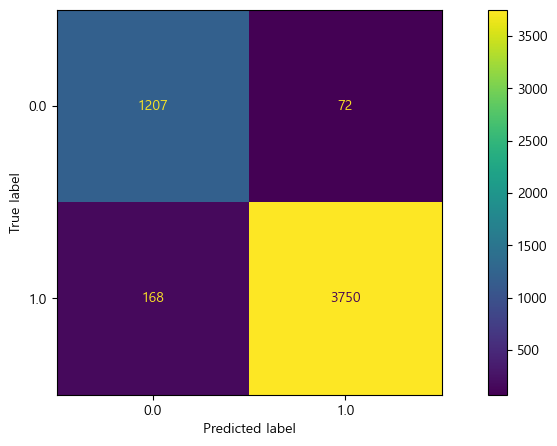

In [32]:
conf_matrix = confusion_matrix(train_target, train_pred, labels=dt.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=dt.classes_) #시각화 시킨 결과를 메모리에 담는 클래스. 이걸 변수에 담기
disp

### 시각화
disp.plot()
plt.show()

In [33]:
"""
<오차행렬(혼동행렬)>
 - 어떠한 유형의 오류가 발생하고 있는지를 나타내는 값
 - 이를 시각화한 것을 오차행렬도(혼동행렬도)라고 칭합니다.
 - 정확도(score)의 값과 오차행렬도의 시각화 결과로 모델을 최종 선정하게 됩니다.
 
<해석 방법>
 - 긍정(Positive)적 오류인지, 부정(Negative)적 오류인지로 해석됩니다.
   (긍정은 1, 부정은 0 입니다.)
   
 - 오류의 종류 : 긍정적(Positive) 오류, 부정적(Negative) 오류로 구분합니다.
 
<오류 해석>
 * 긍정적(Positive) 오류
  - *** 0(부정)을 1(긍정)로 예측한 경우 ***
  - 예측 결과가 맞지는 않음(False)
  - 위험하지 않은 오류라고도 표현합니다.
  - 이론에서는 "FP(False Positive)"라고 칭합니다.
 
 * 부정적(Negative) 오류
  - *** 1(긍정)을 0(부정)으로 예측한 경우 ***
  - 예측 결과가 맞지는 않음(False)
  - 위험한 오류라고도 표현 합니다.
  - 이론에서는 "FN(False Negative)"라고 칭합니다.
  - 정확도가 높더라도, FN의 값이 큰 경우에는 재현율 값이 낮아지기에,
    예측 모델로 사용하는데 신중해야 합니다.(보통 제외)
   
<예측이 잘된 경우>
 * TP(True Positive)
   - 1(긍정)을 1(긍정)로 잘(True) 예측한 경우
   
 * TN(True Negative)
   - 0(부정)을 0(부정)으로 잘(True) 예측한 경우
"""


'\n<오차행렬(혼동행렬)>\n - 어떠한 유형의 오류가 발생하고 있는지를 나타내는 값\n - 이를 시각화한 것을 오차행렬도(혼동행렬도)라고 칭합니다.\n - 정확도(score)의 값과 오차행렬도의 시각화 결과로 모델을 최종 선정하게 됩니다.\n \n<해석 방법>\n - 긍정(Positive)적 오류인지, 부정(Negative)적 오류인지로 해석됩니다.\n   (긍정은 1, 부정은 0 입니다.)\n   \n - 오류의 종류 : 긍정적(Positive) 오류, 부정적(Negative) 오류로 구분합니다.\n \n<오류 해석>\n * 긍정적(Positive) 오류\n  - *** 0(부정)을 1(긍정)로 예측한 경우 ***\n  - 예측 결과가 맞지는 않음(False)\n  - 위험하지 않은 오류라고도 표현합니다.\n  - 이론에서는 "FP(False Positive)"라고 칭합니다.\n \n * 부정적(Negative) 오류\n  - *** 1(긍정)을 0(부정)으로 예측한 경우 ***\n  - 예측 결과가 맞지는 않음(False)\n  - 위험한 오류라고도 표현 합니다.\n  - 이론에서는 "FN(False Negative)"라고 칭합니다.\n  - 정확도가 높더라도, FN의 값이 큰 경우에는 재현율 값이 낮아지기에,\n    예측 모델로 사용하는데 신중해야 합니다.(보통 제외)\n   \n<예측이 잘된 경우>\n * TP(True Positive)\n   - 1(긍정)을 1(긍정)로 잘(True) 예측한 경우\n   \n * TN(True Negative)\n   - 0(부정)을 0(부정)으로 잘(True) 예측한 경우\n'

In [34]:
"""
<평가에 사용되는 값(지표)>
 - 정확도, 정밀도, 재현율, f1-score
 
 * 정확도(Accuracy)
  - 분류 모델에서 score의 값과 동일함
  - 사용패키지 : sklearn.metrics
  - 사용라이브러리 : accuracy_score
  - 예측결과가 실제값을 얼마나 정확하게 예측했는지를 나타낸 값
  - Accuracy = (TP + TN) / (TP + TN + FP + FN)
 
 * 정밀도(Precision)
  - 1(긍정)로 예측한 데이터 중에 실제 1(긍정)로 잘 예측한 값
  - Precision = TP / (TP + FP)
  - 긍정적오류(FP)가 높을 수록 정밀도는 낮아집니다.
  - 사용패키지 : sklearn.metrics
  - 사용라이브러리 : precision_score
 
 * 재현율(Recall)
  - 실제 1(긍정)을 1(긍정)로 잘 예측한 값
  - Recall = TP / (TP + FN)
  - 부정적오류(FN)가 높을 수록 재현율은 낮아집니다.
  - 사용패키지 : sklearn.metrics
  - 사용라이브러리 : recall_score
 
 * f1-score
  - 정밀도와 재현율을 조합하여 하나의 통계치로  반환한 값
  - f1-score = (정밀도 * 재현율) / (정밀도 + 재현율)
  - 사용패키지 : sklearn.metrics
  - 사용라이브러리 : f1_score
 
<최종 모델 선정 방법>
 - 과소 및 과대 적합이 일어나지 않아야 함
 - 재현율과 f1-score가 모두 높으면 우수한 모델로 평가할 수 있음
 - 재현율이 현저히 낮은 경우에는 모델 선정 시 고민 필요
 - 일반화되고, 정확도 높고, 재현율 높고, f1-score가 높은 모델을 선정
   (여러가지 종합적으로 고려하여 판단해야 함)
"""




'\n<평가에 사용되는 값(지표)>\n - 정확도, 정밀도, 재현율, f1-score\n \n * 정확도(Accuracy)\n  - 분류 모델에서 score의 값과 동일함\n  - 사용패키지 : sklearn.metrics\n  - 사용라이브러리 : accuracy_score\n  - 예측결과가 실제값을 얼마나 정확하게 예측했는지를 나타낸 값\n  - Accuracy = (TP + TN) / (TP + TN + FP + FN)\n \n * 정밀도(Precision)\n  - 1(긍정)로 예측한 데이터 중에 실제 1(긍정)로 잘 예측한 값\n  - Precision = TP / (TP + FP)\n  - 긍정적오류(FP)가 높을 수록 정밀도는 낮아집니다.\n  - 사용패키지 : sklearn.metrics\n  - 사용라이브러리 : precision_score\n \n * 재현율(Recall)\n  - 실제 1(긍정)을 1(긍정)로 잘 예측한 값\n  - Recall = TP / (TP + FN)\n  - 부정적오류(FN)가 높을 수록 재현율은 낮아집니다.\n  - 사용패키지 : sklearn.metrics\n  - 사용라이브러리 : recall_score\n \n * f1-score\n  - 정밀도와 재현율을 조합하여 하나의 통계치로  반환한 값\n  - f1-score = (정밀도 * 재현율) / (정밀도 + 재현율)\n  - 사용패키지 : sklearn.metrics\n  - 사용라이브러리 : f1_score\n \n<최종 모델 선정 방법>\n - 과소 및 과대 적합이 일어나지 않아야 함\n - 재현율과 f1-score가 모두 높으면 우수한 모델로 평가할 수 있음\n - 재현율이 현저히 낮은 경우에는 모델 선정 시 고민 필요\n - 일반화되고, 정확도 높고, 재현율 높고, f1-score가 높은 모델을 선정\n   (여러가지 종합적으로 고려하여 판단해야 함)\n'

In [35]:
### 정확도 : fit 이후 사용한 score()함수의 결과와 동일함
train_acc = accuracy_score(train_target, train_pred)
test_acc = accuracy_score(test_target, test_pred)

### 정밀도
train_pre = precision_score(train_target, train_pred)
test_pre = precision_score(test_target, test_pred)

### 재현율
train_rec = recall_score(train_target, train_pred)
test_rec = recall_score(test_target, test_pred)

### F1-score
train_f1 = f1_score(train_target, train_pred)
test_f1 = f1_score(test_target, test_pred)

print(f"훈련 평가결과 : {train_acc:.4f}, {train_pre:.4f}, {train_rec:.4f}, {train_f1:.4f}")
print(f"테스트 평가결과 : {test_acc:.4f}, {test_pre:.4f}, {test_rec:.4f}, {test_f1:.4f}")
print(f"과적합 여부 : {train_acc-test_acc:.4f}")

### (해석)
# - 일반화가 잘 되어있으며, 훈련정확도, 재현율, F1-Score가 모두 좋음
# - 따라서 알콜, 당도, pH 데이터를 이용하여 와인종류를 예측하는 모델로 매우 우수한 모델임

훈련 평가결과 : 0.9538, 0.9812, 0.9571, 0.9690
테스트 평가결과 : 0.8654, 0.9171, 0.9031, 0.9100
과적합 여부 : 0.0884
